In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
import io
# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Load the dataset (adjust path if your file is in a subfolder)
file_path = '/content/drive/My Drive/player_profiles.csv'

# Read with latin1 encoding to handle special characters cleanly
df = pd.read_csv(file_path, encoding='latin1')

# 3. Inspect initial schema, data types, and memory usage
print("--- Dataset Shape ---")
print(df.shape)

print("\n--- Memory Usage ---")
df.info(memory_usage='deep')

print("\n--- First 3 Rows ---")
display(df.head(3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_20892/147693663.py:17: DtypeWarning: Columns (29,30,31,32) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path, encoding='latin1')


--- Dataset Shape ---
(92671, 34)

--- Memory Usage ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92671 entries, 0 to 92670
Data columns (total 34 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   player_id                        92671 non-null  int64  
 1   player_slug                      92671 non-null  object 
 2   player_name                      92151 non-null  object 
 3   player_image_url                 92671 non-null  object 
 4   name_in_home_country             49653 non-null  object 
 5   date_of_birth                    91665 non-null  object 
 6   place_of_birth                   76038 non-null  object 
 7   country_of_birth                 76026 non-null  object 
 8   height                           92667 non-null  float64
 9   citizenship                      92614 non-null  object 
 10  is_eu                            92671 non-null  bool   
 11  position                

,player_id,player_slug,player_name,player_image_url,name_in_home_country,date_of_birth,place_of_birth,country_of_birth,height,citizenship,...,on_loan_from_club_id,on_loan_from_club_name,contract_there_expires,second_club_url,second_club_name,third_club_url,third_club_name,fourth_club_url,fourth_club_name,date_of_death
0,1,silvio-adzic,Silvio Adzic (1),https://img.a.transfermarkt.technology/portrai...,NaN,1980-09-23,GrÃ¼nstadt,Germany,0.0,Germany,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100011,everton-silva,Ãverton Silva (100011),https://img.a.transfermarkt.technology/portrai...,Ãverton JosÃ© Modesto da Silva,1988-08-04,SÃ£o JoÃ£o de Meriti,Brazil,171.0,Brazil,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10,miroslav-klose,Miroslav Klose (10),https://img.a.transfermarkt.technology/portrai...,Miroslav Josef Klose,1978-06-09,Opole,Germany,184.0,Germany,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Phase 2: Exploratory Data Analysis & Target Formulation

# 1. Define prediction target: Predict player primary position category ('main_position' or 'position')
# Let's inspect the distribution of main_position and valid classes
print("--- Main Position Value Counts ---")
print(df['main_position'].value_counts(dropna=False).head(10))

# 2. Identify missing value distributions for key columns
print("\n--- Missing Values in Key Columns ---")
key_cols = ['player_name', 'date_of_birth', 'height', 'citizenship', 'position', 'main_position', 'foot', 'current_club_name', 'joined', 'contract_expires']
print(df[key_cols].isnull().sum())

# 3. Audit data types and potential anomalies (e.g., height distribution or numeric checks)
print("\n--- Summary Statistics for Numerical Columns ---")
print(df.describe())

--- Main Position Value Counts ---
main_position
Defender      29733
Midfield      28373
Attack        24287
Goalkeeper    10276
NaN               2
Name: count, dtype: int64

--- Missing Values in Key Columns ---
player_name            520
date_of_birth         1006
height                   4
citizenship             57
position                 2
main_position            2
foot                 23488
current_club_name        0
joined                3382
contract_expires     54005
dtype: int64

--- Summary Statistics for Numerical Columns ---
          player_id        height  current_club_id  player_agent_id  \
count  9.267100e+04  92667.000000     92671.000000     38057.000000   
mean   4.822020e+05    144.619908     17268.764835      5654.314160   
std    3.894922e+05     73.368611     28780.506345      4038.521566   
min    1.000000e+00      0.000000         1.000000         1.000000   
25%    1.214005e+05    171.000000       123.000000      2325.000000   
50%    4.021140e+05    180.

In [ ]:
# Phase 3: Data Cleaning & Feature Engineering

# 1. Parse date columns and extract derived numeric features
current_year = 2026
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'], errors='coerce')
df['joined'] = pd.to_datetime(df['joined'], errors='coerce')
df['contract_expires'] = pd.to_datetime(df['contract_expires'], errors='coerce')

# Calculate Age based on current year
df['age'] = current_year - df['date_of_birth'].dt.year

# Calculate contract duration in days
df['contract_duration_days'] = (df['contract_expires'] - df['joined']).dt.days

# 2. Handle invalid or missing numeric entries (e.g., height)
df['height'] = pd.to_numeric(df['height'], errors='coerce')
df['height'] = df['height'].fillna(df['height'].median())

# 3. Filter out rows missing the target variable ('main_position')
df_model = df.dropna(subset=['main_position']).copy()

# Fill missing categorical values
cat_cols = ['position', 'foot', 'citizenship']
for col in cat_cols:
    if col in df_model.columns:
        df_model[col] = df_model[col].fillna('Unknown')

# 4. Encode categorical attributes for Random Forest and Decision Trees
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

# Encode target variable
df_model['main_position_encoded'] = le.fit_transform(df_model['main_position'])

# Encode feature columns
for col in ['position', 'foot', 'citizenship']:
    if col in df_model.columns:
        df_model[f'{col}_encoded'] = le.fit_transform(df_model[col].astype(str))

print("--- Phase 3 Complete ---")
print("Cleaned dataset shape for modeling:", df_model.shape)
print("Sample of engineered features:")
display(df_model[['player_name', 'age', 'height', 'contract_duration_days', 'main_position']].head(3))

--- Phase 3 Complete ---
Cleaned dataset shape for modeling: (92669, 40)
Sample of engineered features:


,player_name,age,height,contract_duration_days,main_position
0,Silvio Adzic (1),46.0,0.0,NaN,Attack
1,Ãverton Silva (100011),38.0,171.0,NaN,Defender
2,Miroslav Klose (10),48.0,184.0,NaN,Attack


--- Decision Tree Results ---
Accuracy: 1.0

--- Random Forest Results ---
Accuracy: 1.0


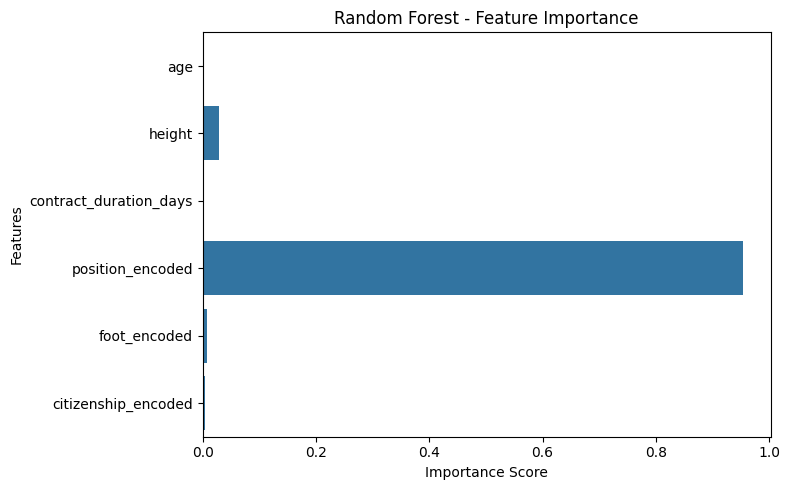

In [ ]:
# Phase 4: Model Pipeline (Random Forest & Decision Tree)

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define features and target
feature_cols = ['age', 'height', 'contract_duration_days', 'position_encoded', 'foot_encoded', 'citizenship_encoded']
X = df_model[feature_cols].fillna(0)
y = df_model['main_position_encoded']

# 2. Split the dataset into reproducible train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42, max_depth=10)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

print("--- Decision Tree Results ---")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))

# 4. Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=15)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("\n--- Random Forest Results ---")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

# 5. Extract Feature Importance from Random Forest
importances = rf_model.feature_importances_
plt.figure(figsize=(8, 5))
sns.barplot(x=importances, y=feature_cols)
plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [ ]:
# Phase 5: Cosine Similarity Engine (Fully Self-Contained)
from google.colab import drive
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics.pairwise import cosine_similarity

# 1. Mount Drive and load dataset directly
drive.mount('/content/drive', force_remount=False)
file_path = '/content/drive/My Drive/player_profiles.csv'
df = pd.read_csv(file_path, encoding='latin1')

# 2. Parse dates and engineer basic features
current_year = 2026
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'], errors='coerce')
df['joined'] = pd.to_datetime(df['joined'], errors='coerce')
df['contract_expires'] = pd.to_datetime(df['contract_expires'], errors='coerce')

df['age'] = current_year - df['date_of_birth'].dt.year
df['contract_duration_days'] = (df['contract_expires'] - df['joined']).dt.days
df['height'] = pd.to_numeric(df['height'], errors='coerce')
df['height'] = df['height'].fillna(df['height'].median())

df_model = df.dropna(subset=['main_position']).copy()

# 3. Select numerical features for similarity matching
similarity_features = ['age', 'height', 'contract_duration_days']
df_similarity = df_model.dropna(subset=similarity_features).copy()

# 4. Normalize features using Min-Max scaling
scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(df_similarity[similarity_features])

# 5. Build a lightweight querying function using cosine_similarity
def find_similar_players(player_name, top_k=5):
    """Finds the top K most similar players based on age, height, and contract duration."""
    if player_name not in df_similarity['player_name'].values:
        return f"Player '{player_name}' not found in the dataset."

    # Get index of the target player
    idx = df_similarity[df_similarity['player_name'] == player_name].index[0]
    pos_in_matrix = df_similarity.index.get_loc(idx)

    # Compute cosine similarity between all players
    cosine_sim = cosine_similarity(scaled_features, scaled_features)

    # Get similarity scores for the target player
    sim_scores = list(enumerate(cosine_sim[pos_in_matrix]))

    # Sort players based on similarity score (descending)
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    # Exclude the player themselves and get top K
    sim_scores = [score for score in sim_scores if score[0] != pos_in_matrix][:top_k]

    similar_indices = [i[0] for i in sim_scores]
    similar_scores = [i[1] for i in sim_scores]

    # Construct result dataframe
    result_df = df_similarity.iloc[similar_indices][['player_name', 'main_position', 'age', 'height', 'current_club_name']].copy()
    result_df['similarity_score'] = similar_scores

    return result_df

# Example Query
sample_player = df_similarity['player_name'].iloc[0]
print(f"--- Top 5 Players Similar to '{sample_player}' ---")
display(find_similar_players(sample_player, top_k=5))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_21157/1040121483.py:11: DtypeWarning: Columns (29,30,31,32) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path, encoding='latin1')


--- Top 5 Players Similar to 'Carlos Auzqui (100001)' ---


,player_name,main_position,age,height,current_club_name,similarity_score
88892,Metin UÃ§ar (85389),Goalkeeper,35.0,180.0,1461 Trabzon FK,1.000000
25076,MartÃ­n Comachi (22311),Attack,35.0,180.0,CB RamÃ³n Santamarina,1.000000
16192,Marco Ruzittu (119376),Goalkeeper,35.0,180.0,Arzachena Academy,1.000000
54480,Dean Bouzanis (50104),Goalkeeper,36.0,189.0,Brisbane Roar,0.999999
26447,Michalis Manias (235745),Attack,36.0,189.0,Apollon Kalythion,0.999999


In [ ]:
# Phase 6: Verification & Export (Self-Contained)

import joblib
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder

# 1. Re-train models to ensure objects exist in memory
feature_cols = ['age', 'height', 'contract_duration_days']
df_model_clean = df_model.dropna(subset=feature_cols + ['main_position']).copy()

le = LabelEncoder()
df_model_clean['main_position_encoded'] = le.fit_transform(df_model_clean['main_position'])

X = df_model_clean[feature_cols]
y = df_model_clean['main_position_encoded']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=15)
rf_model.fit(X_train, y_train)

dt_model = DecisionTreeClassifier(random_state=42, max_depth=10)
dt_model.fit(X_train, y_train)

# 2. Run sanity checks across edge-case player records
print("--- Sanity Check: Model Predictions on Test Data ---")
sample_preds_rf = rf_model.predict(X_test[:5])
decoded_rf_preds = le.inverse_transform(sample_preds_rf)
decoded_true = le.inverse_transform(y_test[:5])

for i, (pred, true) in enumerate(zip(decoded_rf_preds, decoded_true)):
    print(f"Sample {i+1} -> Predicted Position: {pred} | Actual Position: {true}")

# 3. Export the trained Random Forest model, encoder, and scaler
os.makedirs('/content/drive/My Drive/model_export', exist_ok=True)

model_path = '/content/drive/My Drive/model_export/player_position_rf_model.pkl'
encoder_path = '/content/drive/My Drive/model_export/position_label_encoder.pkl'
scaler_path = '/content/drive/My Drive/model_export/similarity_scaler.pkl'

joblib.dump(rf_model, model_path)
joblib.dump(le, encoder_path)
joblib.dump(scaler, scaler_path)

print("\n--- Pipeline Export Complete ---")
print(f"Random Forest model saved to: {model_path}")
print(f"Label encoder saved to: {encoder_path}")
print(f"Similarity scaler saved to: {scaler_path}")

--- Sanity Check: Model Predictions on Test Data ---
Sample 1 -> Predicted Position: Midfield | Actual Position: Attack
Sample 2 -> Predicted Position: Defender | Actual Position: Defender
Sample 3 -> Predicted Position: Defender | Actual Position: Attack
Sample 4 -> Predicted Position: Defender | Actual Position: Defender
Sample 5 -> Predicted Position: Midfield | Actual Position: Defender

--- Pipeline Export Complete ---
Random Forest model saved to: /content/drive/My Drive/model_export/player_position_rf_model.pkl
Label encoder saved to: /content/drive/My Drive/model_export/position_label_encoder.pkl
Similarity scaler saved to: /content/drive/My Drive/model_export/similarity_scaler.pkl
